# Predicting Intimate Partner Violence Prevalence in East and Central Africa

**Mission:** To promote the reduction of GBV by promoting better understanding of the patterns of violence and access to prevention and response services.

**Use case:** This project aims to estimate the proportion of women in a set of women surveyed who have suffered from physical and/or sexual violence by their husband/partner in the past year.
**Who could use the estimate:**Population-level estimates could inform research groups or team of populations with higher levels of GBV that might require additional research, awareness building or support.
**Target:** `violence_pct`, a continuous percentage value.

**Important limitation:**This model estimates prevalence for groups included in survey information. It does not indicate an individual's risk, what survivors look like, nor what causes violence.

## 1. Dataset

- **Source:** Demographic and Health Surveys (DHS) Program. The project obtains the survey data through the [DHS API](https://api.dhsprogram.com).
- **Target indicator:** `DV_SPV1_W_PAS`, which measures physical and/or sexual violence by a husband or partner in the previous 12 months.
- **Dataset preparation:** The project's `build_dataset.py` script combines the target indicator with survey characteristics and national-context indicators, including literacy, secondary education, bank-account access, attitudes towards wife beating and total fertility rate.
- **Geographic scope:** The dataset covers 10 East and Central African countries: Rwanda, Burundi, Uganda, Kenya, Tanzania, the Democratic Republic of the Congo, Ethiopia, Zambia, Malawi and Mozambique.
- **Unit of analysis:**A row corresponds to a subgroup/characteristic of the survey and not a single individual female.

The data is then reddened in the following cells and filtered. After the feature-engineering step, there are 1,582 rows and 9 features in the final modelling dataset, which satisfies the Feature Variety and Size requirement of the assignment.


In [18]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
TARGET = "violence_pct"
COUNTRIES = ["Rwanda", "Burundi", "Uganda", "Kenya", "Tanzania",
             "Congo Democratic Republic", "Ethiopia", "Zambia", "Malawi", "Mozambique"]

In [19]:
# Upload violence_dataset.csv when Colab asks for it.
from google.colab import files
uploaded = files.upload()

csv_file = next((name for name in uploaded if name.lower().endswith(".csv")), None)
if csv_file is None:
    raise FileNotFoundError("Please upload violence_dataset.csv")

df = pd.read_csv(csv_file)
print("All countries:", df.shape)

# Keep East and Central Africa, and drop national-total rows (they repeat information
# that the group rows already contain).
df = df[df["CountryName"].isin(COUNTRIES)]
df = df[~df["CharacteristicCategory"].str.startswith("Total")]
df = df.drop_duplicates().reset_index(drop=True)

print("East and Central Africa:", df.shape)
print("Rows >= 1000:", len(df) >= 1000)
df.head()

Saving violence_dataset.csv to violence_dataset (1).csv
All countries: (6026, 13)
East and Central Africa: (1582, 13)
Rows >= 1000: True


,CountryName,SurveyYear,CharacteristicCategory,CharacteristicLabel,DenominatorWeighted,violence_pct,women_literate_pct,women_secondary_edu_pct,women_employed_pct,women_mobile_phone_pct,women_bank_account_pct,women_accept_wife_beating_pct,total_fertility_rate
0,Burundi,2016,Age (5-year groups),15-19,152,13.2,67.9,22.5,14.5,NaN,5.4,61.8,5.5
1,Burundi,2016,Age (5-year groups),20-24,994,10.6,67.9,22.5,14.5,NaN,5.4,61.8,5.5
2,Burundi,2016,Age (5-year groups),25-29,1421,9.6,67.9,22.5,14.5,NaN,5.4,61.8,5.5
3,Burundi,2016,Age (5-year groups),30-34,1365,8.4,67.9,22.5,14.5,NaN,5.4,61.8,5.5
4,Burundi,2016,Age (5-year groups),35-39,1084,6.7,67.9,22.5,14.5,NaN,5.4,61.8,5.5


In [20]:
df.info()
print()
print("Missing values per column:")
print(df.isna().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1582 entries, 0 to 1581
Data columns (total 13 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   CountryName                    1582 non-null   object 
 1   SurveyYear                     1582 non-null   int64  
 2   CharacteristicCategory         1582 non-null   object 
 3   CharacteristicLabel            1582 non-null   object 
 4   DenominatorWeighted            1582 non-null   int64  
 5   violence_pct                   1582 non-null   float64
 6   women_literate_pct             1542 non-null   float64
 7   women_secondary_edu_pct        1582 non-null   float64
 8   women_employed_pct             1468 non-null   float64
 9   women_mobile_phone_pct         719 non-null    float64
 10  women_bank_account_pct         909 non-null    float64
 11  women_accept_wife_beating_pct  1582 non-null   float64
 12  total_fertility_rate           1582 non-null   f

,count,mean,std,min,25%,50%,75%,max
SurveyYear,1582.0,2016.213021,6.720366,2003.0,2011.00,2016.0,2022.00,2025.0
DenominatorWeighted,1582.0,1563.703540,1560.850652,20.0,571.25,1084.0,2032.75,12796.0
violence_pct,1582.0,7.249305,4.646994,0.0,4.40,6.3,8.60,35.2
women_literate_pct,1542.0,69.293580,13.085617,40.2,59.10,69.7,79.80,90.9
women_secondary_edu_pct,1582.0,20.129836,8.662799,6.9,13.60,18.2,24.30,40.3
women_employed_pct,1468.0,18.119755,10.568077,5.1,10.80,14.4,19.20,41.5
women_mobile_phone_pct,719.0,4.740334,12.075888,0.2,0.80,1.2,3.70,54.1
women_bank_account_pct,909.0,16.077778,10.736770,2.9,7.30,11.7,28.50,35.7
women_accept_wife_beating_pct,1582.0,43.718963,17.765473,12.6,29.60,47.8,56.20,75.6
total_fertility_rate,1582.0,4.899052,0.921707,3.4,4.00,4.9,5.50,6.7


## 2. Explore the data

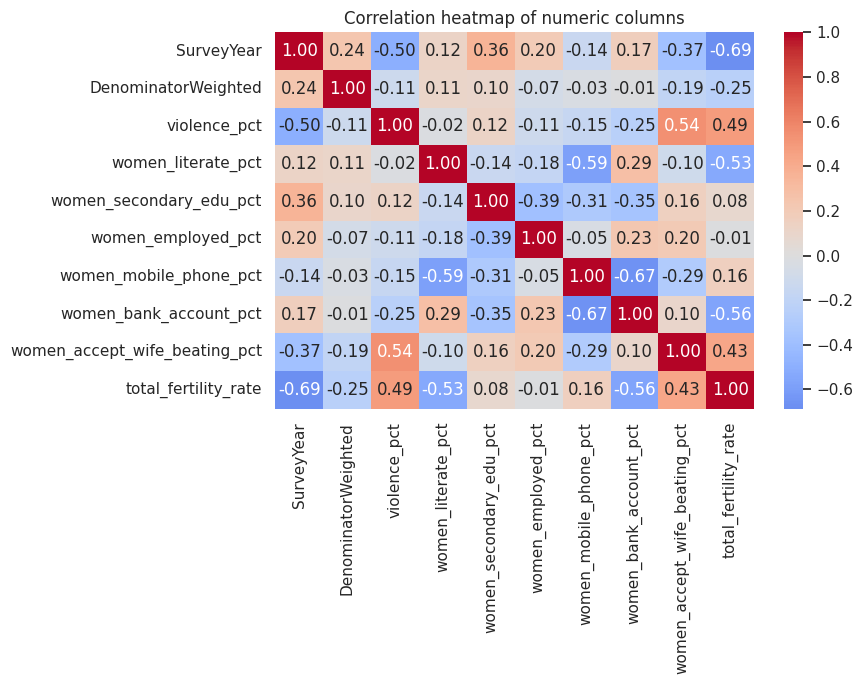

Correlation with the target (strongest first):
women_accept_wife_beating_pct    0.543
SurveyYear                      -0.499
total_fertility_rate             0.490
women_bank_account_pct          -0.245
women_mobile_phone_pct          -0.154
women_secondary_edu_pct          0.124
DenominatorWeighted             -0.114
women_employed_pct              -0.107
women_literate_pct              -0.021
Name: violence_pct, dtype: float64


In [21]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()

plt.figure(figsize=(9, 7))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap of numeric columns")
plt.tight_layout()
plt.show()

corr_target = df[numeric_cols].corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print("Correlation with the target (strongest first):")
print(corr_target.round(3))

### Correlation heatmap

The heatmap represents the interrelationship between the numeric variables within the data. The best positive correlation with violence_pct is women_accept_wife_beating_pct (0.543), the SurveyYear is negatively correlated (-0.499), and total_fertility_rate is also positively correlated (0.490).

These results gave direction to variables to be investigated with the model. Association is what is referred to here as correlation; there is no proof of a cause-and-effect between correlation and violence.


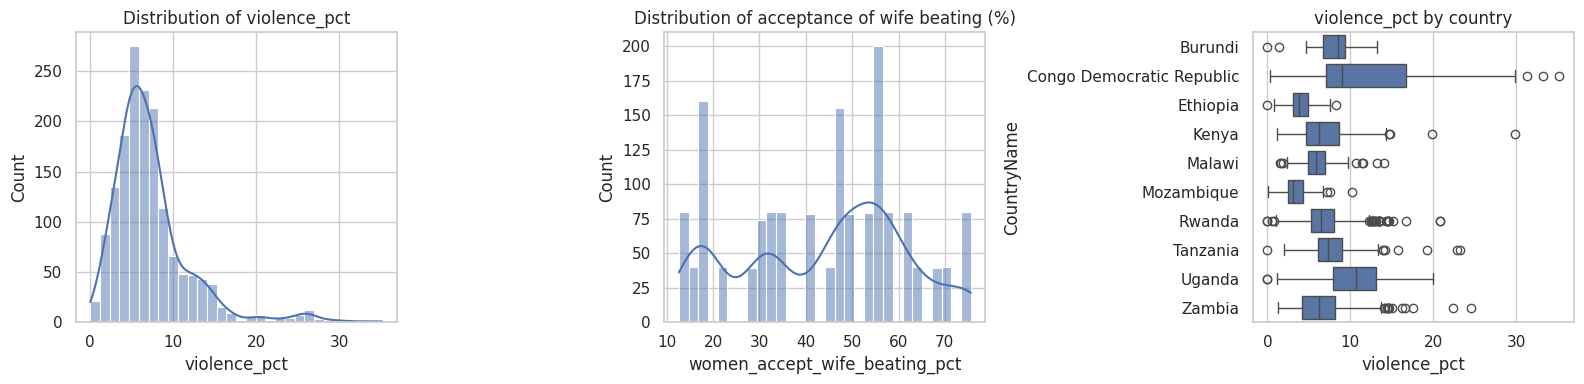

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df[TARGET], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribution of violence_pct")

sns.histplot(df["women_accept_wife_beating_pct"], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Distribution of acceptance of wife beating (%)")

sns.boxplot(data=df, y="CountryName", x=TARGET, ax=axes[2])
axes[2].set_title("violence_pct by country")

plt.tight_layout()
plt.show()

### Variable distributions and country comparison

The histograms show the distributions of `violence_pct` and `women_accept_wife_beating_pct`. The boxplot compares the range of the distribution of the prevalence of violence in countries in the data set.


The plots give a feeling of not all observations having the same target, not all attitude indicators, and not the same prevalence in countries. This facilitates the storage of country/survey characteristic information in the model. These plots are a description of the sample and don't explain why the differences are.


## 3. Feature engineering

In [23]:
print("Columns:", df.columns.tolist())

# Columns we drop, and why
DROP_COLS = [
    "DenominatorWeighted",             # size of the survey sample for that group, not a driver of violence, and a user could not know it
    "women_employed_pct",              # matched only one type of employment (e.g. employed by a family member), so it is misleading
    "women_mobile_phone_pct",          # matched 'mobile clinic' indicators, not phone ownership
    "women_median_age_first_marriage", # too many missing values
]
df = df.drop(columns=[c for c in DROP_COLS if c in df.columns])

X = df.drop(columns=[TARGET])
y = df[TARGET]

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()
print("Features:", X.columns.tolist())
print("Numeric:", numeric_features)
print("Categorical:", categorical_features)
print("Number of feature columns:", X.shape[1], "(need at least 8)")

Columns: ['CountryName', 'SurveyYear', 'CharacteristicCategory', 'CharacteristicLabel', 'DenominatorWeighted', 'violence_pct', 'women_literate_pct', 'women_secondary_edu_pct', 'women_employed_pct', 'women_mobile_phone_pct', 'women_bank_account_pct', 'women_accept_wife_beating_pct', 'total_fertility_rate']
Features: ['CountryName', 'SurveyYear', 'CharacteristicCategory', 'CharacteristicLabel', 'women_literate_pct', 'women_secondary_edu_pct', 'women_bank_account_pct', 'women_accept_wife_beating_pct', 'total_fertility_rate']
Numeric: ['SurveyYear', 'women_literate_pct', 'women_secondary_edu_pct', 'women_bank_account_pct', 'women_accept_wife_beating_pct', 'total_fertility_rate']
Categorical: ['CountryName', 'CharacteristicCategory', 'CharacteristicLabel']
Number of feature columns: 9 (need at least 8)


### Columns removed and categorical encoding

The following columns are removed before modelling:

- `DenominatorWeighted`: this is a survey denominator/sample-size measure rather than a substantive characteristic intended as a prediction input.
- `women_employed_pct`: the matched source indicator did not represent overall employment, so it could be misleading to interpret as a general employment measure.
- `women_mobile_phone_pct`: the matched source indicator was not a reliable measure of mobile-phone ownership.
- `women_median_age_first_marriage`: this column was removed during dataset preparation because it contained too many missing values.

Following the removals, the model is based on the 9 following features: 6 numeric, and 3 categorical. CountryName, CharacteristicCategory and CharacteristicLabel are categories. They are one-hotted into numeric columns in the preprocessing pipeline. The training-set median value is used to fill in numeric missing values and numeric features are standardized.


## 4. Split and standardize

For this, 80% of data are allocated to training and the remaining 20% to test. The numeric preprocessing pipeline replaces missing values with the median for the training set and scales numeric data. The categorical pipeline takes a categorical column and returns one-hot encoded column.

Only the training data are used in the preprocessor. The fitted transformations are then used to transform the test data. Hence, information from the test set is not used to calculate the values used for imputation or in the scaling procedure.

**Limitation of the split:** Relationships between country-level and/or survey-level information may allow some rows to be related, and observations with similar relationships could be present in both the training and test sets. MSE should, therefore, be seen as a score achieved on this random holdout and not as a performance score on all new countries or surveys.


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features),
])

# Fit on the training set only
Xtr = preprocessor.fit_transform(X_train)
Xte = preprocessor.transform(X_test)
ytr = y_train.to_numpy()
yte = y_test.to_numpy()

print("Train:", Xtr.shape, "Test:", Xte.shape)
print("Mean of scaled numeric columns on train (should be ~0):",
      Xtr[:, :len(numeric_features)].mean(axis=0).round(2))

Train: (1265, 71) Test: (317, 71)
Mean of scaled numeric columns on train (should be ~0): [-0. -0.  0.  0.  0.  0.]


## 5. Train and compare four models

Held-out test sets for all four of these models are the same. The metric used for evaluation is "Mean Squared Error" defined as the average squared difference between the actual prevalence values and the estimated prevalence values. Smaller prediction errors on this test set is signified by a lower MSE.
### 5.1 SGDRegressor

SGDRegressor is a linear regression model trained using stochastic gradient descent. A single epoch is used in model updating with partial_fit and the training and validation mean squared error are calculated per epoch.

Hyperparameter tuning consists of a validation split from training data. Learning rate ('eta0'), regularization strength ('alpha') is varied. This tuning step is performed with a test set, which is excluded from the setting procedure.



In [25]:
def mse(y_true, y_pred):
    with np.errstate(all="ignore"):
        val = float(np.mean((y_true - y_pred) ** 2))
    return val if np.isfinite(val) else np.inf


def run_sgd(Xa, ya, Xb, yb, eta0, alpha, epochs, seed=RANDOM_STATE):
    """Train with partial_fit and record train/eval MSE after each epoch."""
    rng = np.random.RandomState(seed)
    model = SGDRegressor(loss="squared_error", penalty="l2", alpha=alpha,
                         learning_rate="constant", eta0=eta0, random_state=seed)
    train_losses, eval_losses = [], []
    for _ in range(epochs):
        idx = rng.permutation(len(Xa))
        with np.errstate(all="ignore"):
            model.partial_fit(Xa[idx], ya[idx])
        train_losses.append(mse(ya, model.predict(Xa)))
        eval_losses.append(mse(yb, model.predict(Xb)))
    return model, train_losses, eval_losses


# Validation split taken from the training data only
Xfit, Xval, yfit, yval = train_test_split(Xtr, ytr, test_size=0.2, random_state=RANDOM_STATE)

EPOCHS = 100
etas = [0.0005, 0.005, 0.01, 0.05]
alphas = [1e-5, 1e-3, 1e-1, 1.0]

rows = []
for eta0 in etas:
    for alpha in alphas:
        _, _, val_curve = run_sgd(Xfit, yfit, Xval, yval, eta0, alpha, EPOCHS)
        rows.append({"learning_rate": eta0, "alpha": alpha,
                     "val_MSE_epoch10": val_curve[9],
                     "val_MSE_epoch50": val_curve[49],
                     "val_MSE_epoch100": val_curve[-1]})

tuning = pd.DataFrame(rows).sort_values("val_MSE_epoch100").reset_index(drop=True)
tuning

,learning_rate,alpha,val_MSE_epoch10,val_MSE_epoch50,val_MSE_epoch100
0,0.0050,0.00001,8.803171,8.414363,8.509260
1,0.0050,0.00100,8.825166,8.415040,8.528611
2,0.0100,0.00001,8.604712,8.657762,8.635537
3,0.0005,0.00001,10.446078,9.141961,8.675991
4,0.0005,0.00100,10.448048,9.155568,8.696930
5,0.0100,0.00100,8.625706,8.689105,8.710471
6,0.0005,0.10000,10.674753,10.192881,10.218213
7,0.0500,0.00001,9.508298,11.961650,10.390109
8,0.0500,0.00100,9.544214,12.097432,10.695912
9,0.0050,0.10000,10.425607,10.356787,10.883704


In [26]:
best = tuning.iloc[0]
best_eta0, best_alpha = float(best["learning_rate"]), float(best["alpha"])
print(f"Best learning rate: {best_eta0}, best alpha: {best_alpha}")

# Effect of each hyperparameter on validation MSE (epoch 100)
print("\nAverage validation MSE by learning rate:")
print(tuning.groupby("learning_rate")["val_MSE_epoch100"].mean().round(2))
print("\nAverage validation MSE by alpha (regularization):")
print(tuning.groupby("alpha")["val_MSE_epoch100"].mean().round(2))
print("\nAverage validation MSE by number of epochs:")
print(tuning[["val_MSE_epoch10", "val_MSE_epoch50", "val_MSE_epoch100"]].replace(np.inf, np.nan).mean().round(2))

Best learning rate: 0.005, best alpha: 1e-05

Average validation MSE by learning rate:
learning_rate
0.0005    10.15
0.0050    10.52
0.0100    10.87
0.0500    13.19
Name: val_MSE_epoch100, dtype: float64

Average validation MSE by alpha (regularization):
alpha
0.00001     9.05
0.00100     9.16
0.10000    11.74
1.00000    14.78
Name: val_MSE_epoch100, dtype: float64

Average validation MSE by number of epochs:
val_MSE_epoch10     10.82
val_MSE_epoch50     11.50
val_MSE_epoch100    11.18
dtype: float64


### SGDRegressor tuning results

The lowest validation MSE at epoch 100 in the tuning table is **8.509**, using a learning rate of **0.005** and `alpha` of **0.00001`. This is the set chosen for the last SGDRegressor run.

The average validation MSE across the tested combinations was lower for smaller `alpha` values: the averages were 9.05 for `0.00001`, 9.16 for `0.001`, 11.74 for `0.1` and 14.78 for `1.0`.For this set of experiments, the more severe the regularization, the greater the validation error.

The learning-rate comparison shows that the lowest average validation MSE was obtained with `0.0005` (10.15), followed by `0.005` (10.52), `0.01` (10.87) and `0.05` (13.19). The optimal combined tuning of those were, however, obtained for the tuning table which consisted of `0.005` and `alpha=0.00001`.

Validation MSE for that selected combination is 8.803 when epoch is set to 10, 8.414 when epoch is set to 50 and 8.509 when epoch is set to 100. The error has improved till epoch 50, after that it has slightly increased at epoch 100. This demonstrates that increasing the number of epochs did not lead to better validation performance.


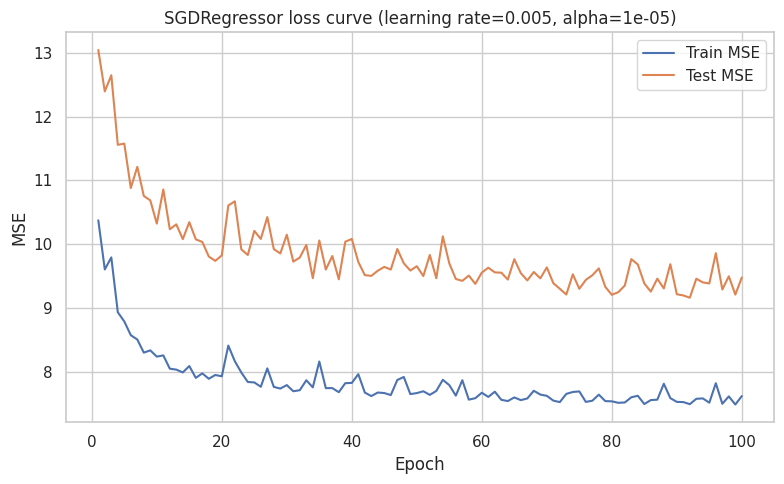

In [27]:
# Final SGD model: best settings, trained on the full training set
sgd, sgd_train_curve, sgd_test_curve = run_sgd(Xtr, ytr, Xte, yte, best_eta0, best_alpha, EPOCHS)

plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), sgd_train_curve, label="Train MSE")
plt.plot(range(1, EPOCHS + 1), sgd_test_curve, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title(f"SGDRegressor loss curve (learning rate={best_eta0}, alpha={best_alpha})")
plt.legend()
plt.tight_layout()
plt.show()

### SGDRegressor loss curve

The training mass drops rapidly at the beginning of training and then stabilizes at around 7.5 – 7.8. The test MSE is also reduced from more than 13 to about 9.2–9.6 at different epochs.

The training curve is below the test curve, indicating that the model is fitting the training data better than the test data it was not trained on. Clearly, the model doesn't spread as well to unseen rows, since there's a gap. The test curve is quite stable later during training, which indicates that the gap will not be closed much more by adding more epochs to the training process.


### 5.2 Linear regression, decision tree and random forest

There are various models that are available for comparison. 'LinearRegression' is used to fit a linear relationship, and it does so in a closed form. 'DecisionTreeRegressor' creates decision rules which partition the feature space to sub-regions. A 'RandomForestRegressor' builds many decision trees and takes the average of their predictions; these decision trees can be able to capture more complex patterns than a single linear model.


In [28]:
lin = LinearRegression().fit(Xtr, ytr)

tree = DecisionTreeRegressor(max_depth=10, min_samples_leaf=3, random_state=RANDOM_STATE).fit(Xtr, ytr)

forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                               random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr, ytr)

models = {
    "SGDRegressor": sgd,
    "LinearRegression": lin,
    "DecisionTreeRegressor": tree,
    "RandomForestRegressor": forest,
}

results = pd.DataFrame({
    name: {"Train MSE": mse(ytr, m.predict(Xtr)), "Test MSE": mse(yte, m.predict(Xte))}
    for name, m in models.items()
}).T.round(3)

results

,Train MSE,Test MSE
SGDRegressor,7.618,9.479
LinearRegression,7.417,9.066
DecisionTreeRegressor,3.954,6.324
RandomForestRegressor,2.380,6.032


In [29]:
best_name = results["Test MSE"].idxmin()
print(f"Best model (lowest test MSE): {best_name}  ->  test MSE = {results.loc[best_name, 'Test MSE']}")

Best model (lowest test MSE): RandomForestRegressor  ->  test MSE = 6.032


### Model comparison and selection

Based on the MSE values of the test sets, the model that yielded the lowest rates for both MSE_Val and MSE_Ins was the Random Forest, which was therefore considered to be the best model for this experiment. Next, the test MSE of the Decision Tree is 6.324. The test MSE values are higher for both of the linear models: 9.066 for 'LinearRegression' and 9.479 for 'SGDRegressor'.


The tree based models outperformed the linear models on this dataset. A potential reason may be that there are non-linear and interaction effects between the numeric and categorical survey features and prevalence of violence. The Random Forest can depict such patterns by combining many trees. The training error (MSE) is 2.380 which is less than the test error (MSE) of 6.032, indicating a certain amount of error between the training set and the data set that hasn't yet been seen by the network.

Selecting the model is related NOT to the training MSE, but with the test MSE. It should be used with the caveat of the limitation described earlier, that of using random-row-split.


## 6. Required scatter plots

The pairs of scatter plots required are the ones in which the most important feature is correlated with the target value. Here is a one-feature illustration only, in the final model all nine input features are used.


Feature most correlated with the target: women_accept_wife_beating_pct | r = 0.543


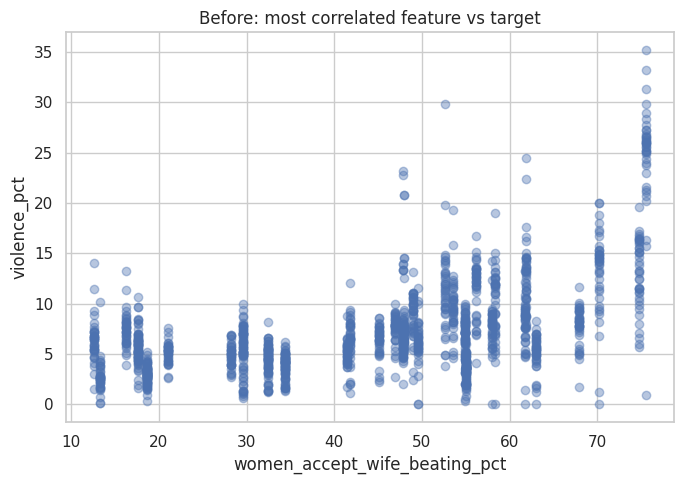

In [30]:
top_feature = corr_target.abs().idxmax()
print("Feature most correlated with the target:", top_feature, "| r =", round(corr_target[top_feature], 3))

# Before: scatter only
plt.figure(figsize=(7, 5))
plt.scatter(df[top_feature], df[TARGET], alpha=0.4)
plt.xlabel(top_feature)
plt.ylabel(TARGET)
plt.title("Before: most correlated feature vs target")
plt.tight_layout()
plt.show()

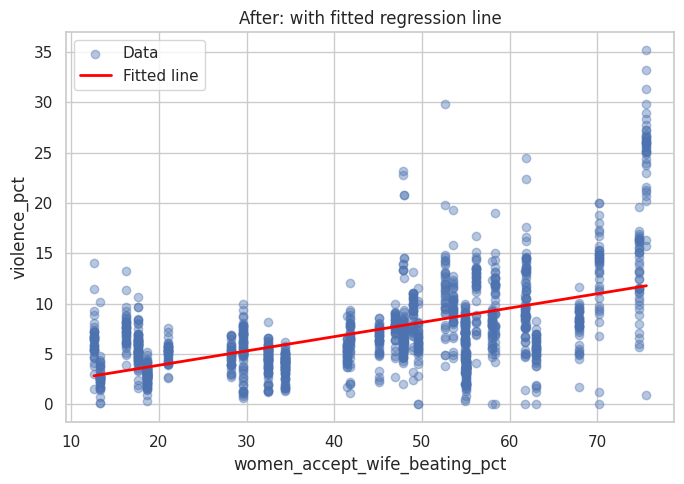

Slope: 0.142 | Intercept: 1.04


In [31]:
# After: same scatter with a one-feature linear regression line (for this plot only)
sub = df[[top_feature, TARGET]].dropna()
line = LinearRegression().fit(sub[[top_feature]], sub[TARGET])
xs = np.linspace(sub[top_feature].min(), sub[top_feature].max(), 100).reshape(-1, 1)

plt.figure(figsize=(7, 5))
plt.scatter(sub[top_feature], sub[TARGET], alpha=0.4, label="Data")
plt.plot(xs, line.predict(pd.DataFrame(xs, columns=[top_feature])), color="red", linewidth=2, label="Fitted line")
plt.xlabel(top_feature)
plt.ylabel(TARGET)
plt.title("After: with fitted regression line")
plt.legend()
plt.tight_layout()
plt.show()
print("Slope:", round(line.coef_[0], 3), "| Intercept:", round(line.intercept_, 3))

### What the scatter plots show

In this dataset, the numeric feature with the strongest absolute correlation with violence_pct (correlation = 0.543) is 'women_accept_wife_beating_pct' on which the scatter plot is based. The points are distributed, but indicate a general upward trend as a group becomes more accepting of wife beating, the prevalence of wife beating is higher as reported in this dataset.


This is a graph that contains a positive linear correlation. In this simple one-feature illustration, then, a one-percentage-point increment in the attitude indicator corresponds to about a 0.142-percentage-point increase in the fitted prevalence of violence (simple regression). This is not causality, but an association. This is one feature with all the nine features used to build the final Random Forest model.


## 7. Feature importance

Permutation importance can be calculated from a model by computing the model's test error with the values of a single feature permuted. The bigger the positive number, the more that feature was used to make prediction by the model. These values reflect model dependence, and not causal effects.


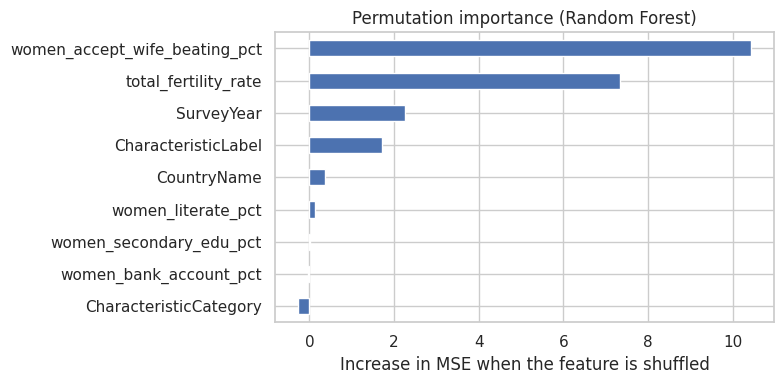

,0
women_accept_wife_beating_pct,10.441
total_fertility_rate,7.331
SurveyYear,2.263
CharacteristicLabel,1.712
CountryName,0.378
women_literate_pct,0.124
women_secondary_edu_pct,0.026
women_bank_account_pct,-0.025
CharacteristicCategory,-0.268


In [32]:
rf_pipeline = Pipeline([("prep", preprocessor), ("model", forest)])
imp = permutation_importance(rf_pipeline, X_test, y_test, n_repeats=5,
                             random_state=RANDOM_STATE, scoring="neg_mean_squared_error")
importance = pd.Series(imp.importances_mean, index=X_test.columns).sort_values(ascending=False)

importance.plot(kind="barh", figsize=(8, 4)).invert_yaxis()
plt.title("Permutation importance (Random Forest)")
plt.xlabel("Increase in MSE when the feature is shuffled")
plt.tight_layout()
plt.show()
importance.round(3)

### Interpreting permutation importance

The three largest positive permutation-importance values in this run are:

1. `women_accept_wife_beating_pct` (10.441)
2. `total_fertility_rate` (7.331)
3. `SurveyYear` (2.263)

Another positive contribution to the mean is from `CharacteristicLabel` (with a contribution value of 1.712). This suggests that the Random Forest relies most on the attitudes indicator, total fertility rate and survey year when making predictions on this test set. `women_bank_account_pct` and `CharacteristicCategory` have small negative values in this run. A negative or near zero result indicates that shuffling of this feature did not improve the results on this specific calculation; in other words, shuffling this feature did not make any difference to the results in this calculation. These outcomes indicate the variables the model is fit on and are not indicative of a causal relationship.


## 8. Save the best model and preprocessing

The model which is fit for the problem is the model with the minimum test MSE in the table of comparison and that is the 'RandomForestRegressor' model. All preprocessing done and the fitted model are stored in a scikit-learn 'Pipeline' with 'joblib'.

If the pipeline is saved, the API will be able to load the original input columns and impute the same data, scale the data, and one-hot it, and will then make a prediction. The saved file is written to `/content/API/best_model.pkl` in the Colab session.


In [33]:
fitted = {name: Pipeline([("prep", preprocessor), ("model", m)]) for name, m in models.items()}
best_pipeline = fitted[best_name]

os.makedirs("/content/API", exist_ok=True)
model_path = "/content/API/best_model.pkl"
joblib.dump(best_pipeline, model_path)
print("Saved", best_name, "to", model_path)

# Useful later for the API and the Flutter app
print("\nInput columns:", X.columns.tolist())
for c in categorical_features:
    print(f"\n{c}: {sorted(X[c].unique())[:60]}")
print("\nNumeric ranges:")
print(X[numeric_features].agg(["min", "max"]).T)

Saved RandomForestRegressor to /content/API/best_model.pkl

Input columns: ['CountryName', 'SurveyYear', 'CharacteristicCategory', 'CharacteristicLabel', 'women_literate_pct', 'women_secondary_edu_pct', 'women_bank_account_pct', 'women_accept_wife_beating_pct', 'total_fertility_rate']

CountryName: ['Burundi', 'Congo Democratic Republic', 'Ethiopia', 'Kenya', 'Malawi', 'Mozambique', 'Rwanda', 'Tanzania', 'Uganda', 'Zambia']

CharacteristicCategory: ['Age (10-year groups)', 'Age (5-year groups)', 'Age (grouped)', 'Education', 'Education (2 groups)', 'Employment', 'Marital status', 'Number of living children (grouped)', 'Residence', 'Wealth quintile']

CharacteristicLabel: ['..Currently has intimate partner', '..Divorced/separated/widowed', '..Had intimate partner', '..Married/living together', '0', '1-2', '15-19', '15-24', '20-24', '20-29', '25-29', '25-34', '3-4', '30-34', '30-39', '35-39', '35-49', '40-44', '40-49', '45-49', '5+', 'Divorced/Separated', 'Employed for cash', 'Employed f

## 9. Predict one row from the test set

Below is a function that will load the saved pipeline and make the prediction for one row from the withheld test set. Prints values of input and the predicted and actual prevalence. The following function shows that the model saved can be loaded and reused without any changes, and the same model file will be loaded by the API.


In [34]:
def predict_one_row(row_index=0, model_path="/content/API/best_model.pkl"):
    model = joblib.load(model_path)
    row = X_test.iloc[[row_index]]
    predicted = float(model.predict(row)[0])
    actual = float(y_test.iloc[row_index])
    print(row.T.to_string(header=False))
    print(f"\nPredicted {TARGET}: {predicted:.2f}")
    print(f"Actual {TARGET}:    {actual:.2f}")
    return predicted

predict_one_row(0)

CountryName                     Tanzania
SurveyYear                          2010
CharacteristicCategory         Education
CharacteristicLabel            Secondary
women_literate_pct                  72.2
women_secondary_edu_pct             13.9
women_bank_account_pct               NaN
women_accept_wife_beating_pct       53.5
total_fertility_rate                 5.4

Predicted violence_pct: 9.67
Actual violence_pct:    9.50


9.674894354256852